<a href="https://colab.research.google.com/github/DhaiHamoud/Fraud-Detection-in-the-Financial-Transaction-Market/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import gdown, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, numpy as np
gdown.download(id='1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs', output='clean.parquet', quiet=False)
df = pd.read_parquet('clean.parquet')

Downloading...
From (original): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs
From (redirected): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs&confirm=t&uuid=65eb1773-7f0d-433a-9b3d-2672791aa98a
To: /content/clean.parquet
100%|██████████| 139M/139M [00:01<00:00, 118MB/s]


## 1. Target Distribution — **Turki**

In [16]:
df["is_fraud"].value_counts()

,count
is_fraud,
0,1842743
1,9651


Number of legitimate transactions are 1,842,743 , and the fraud ones are 9651.

In [17]:
df["is_fraud"].value_counts(normalize=True) * 100

,proportion
is_fraud,
0,99.478999
1,0.521001


99.48% of the transactions are legitimate, and the fraud transcations are 0.52%

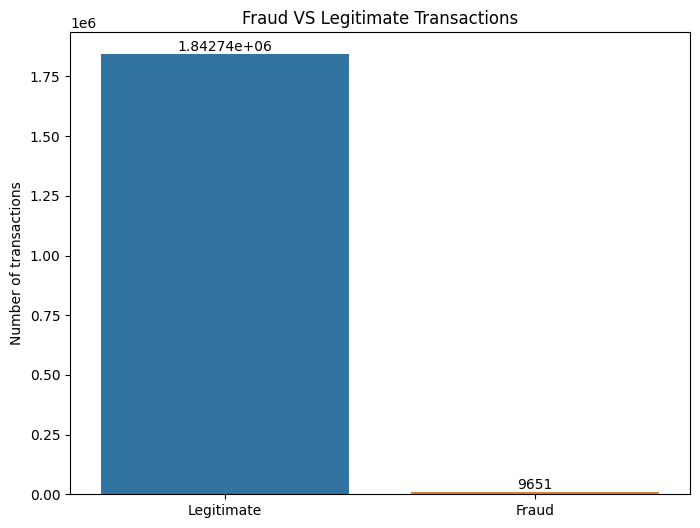

In [18]:
plt.figure(figsize=(8,6))
fig = sns.countplot(df, x="is_fraud",hue="is_fraud", legend=False);
plt.title("Fraud VS Legitimate Transactions")
fig.set_xticks([0, 1])
fig.set_xticklabels(["Legitimate", "Fraud"])
plt.ylabel("Number of transactions")
for c in fig.containers:
    fig.bar_label(c)
plt.xlabel("");

**Observation:** The dataset is highly imbalanced. Legitimate transactions are far more common than fraud, so the fraud bar is barely visible.

**Fraud is 0.52% of all transactions** (9,651 out of 1,852,394), while legitimate transactions are 99.48%. The fraud bar is barely visible because the data is highly imbalanced.

**Effect on accuracy:** Accuracy is not a reliable metric here. A model that always predicts "legitimate" would score about 99.5% accuracy while catching no fraud at all.

## 2. Amount Distribution — Abdulmohsen

In [19]:
#Summary statistics for transaction amounts
df['amt'].describe()

,amt
count,1.852394e+06
mean,7.006357e+01
std,1.592540e+02
min,1.000000e+00
25%,9.640000e+00
50%,4.745000e+01
75%,8.310000e+01
max,2.894890e+04


**Summary:** Transaction amounts range from \$1.00 to \$28,948.90. The middle 50% fall between \$9.64 and \$83.10, with a median of \$47.45 and a mean of \$70.06.

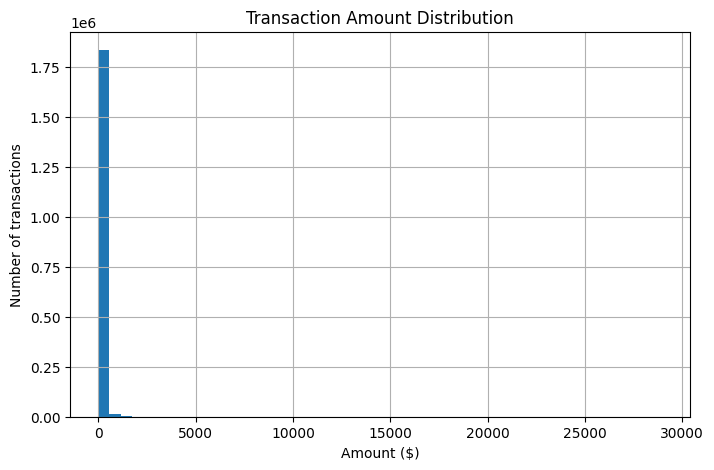

In [20]:
#Plot the distribution of transaction amounts
plt.figure(figsize=(8, 5))
df['amt'].hist(bins=50)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount ($)')
plt.ylabel('Number of transactions')
plt.show()

**Observation:** Transaction amounts are strongly right-skewed: 75% are at or below \$83.10, while the maximum reaches \$28,948.90. The mean (\$70.06) is higher than the median (\$47.45), reflecting the influence of large amounts.

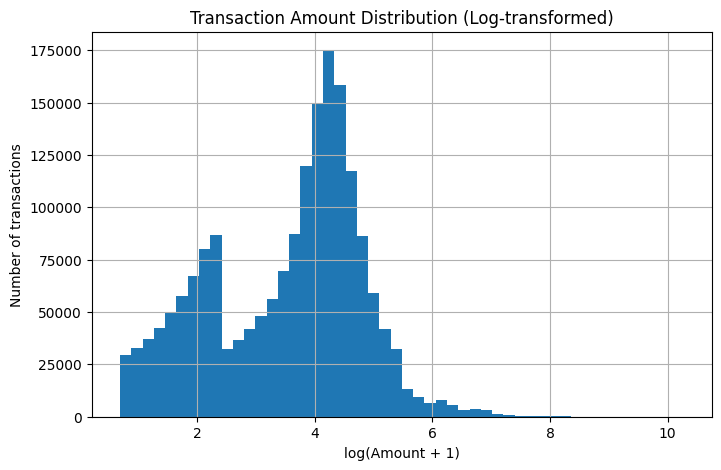

In [21]:
#Plot amounts after a log transformation
plt.figure(figsize=(8, 5))
np.log1p(df['amt']).hist(bins=50)
plt.title('Transaction Amount Distribution (Log-transformed)')
plt.xlabel('log(Amount + 1)')
plt.ylabel('Number of transactions')
plt.show()

**Observation:** The log transformation makes the distribution clearer, revealing a main peak around log(Amount + 1) = 4.2 and a smaller peak near 2.3. Large amounts remain in the right tail, but no longer compress the smaller amounts into a single dominant bar.

**Unexpected:** The log-transformed histogram reveals two distinct peaks that were not visible on the original scale; the reason for this pattern needs further investigation.

## 3. Hour and Age Distribution — Rayan

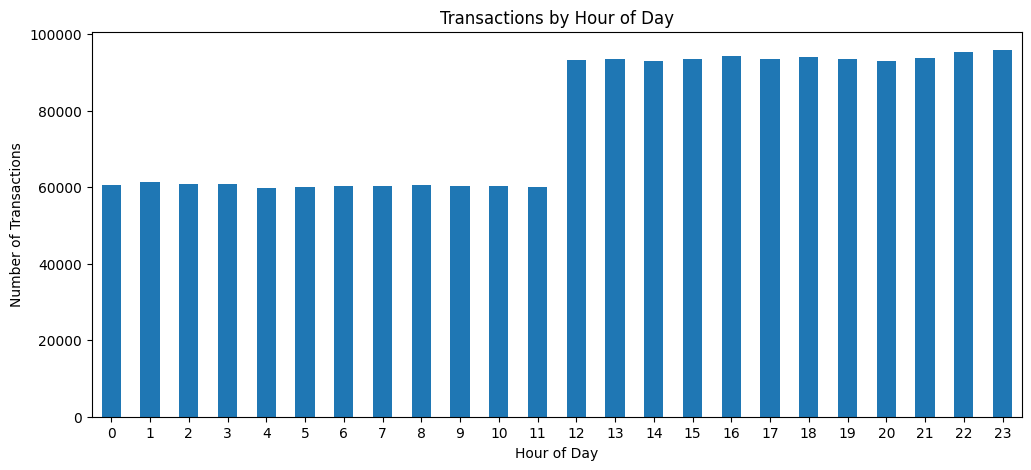

Busiest hour: 23
Transactions: 95902
Quietest hour: 4
Transactions: 59938


In [22]:

# Extract the transaction hour (0-23)
hour = df['trans_date_trans_time'].dt.hour

# Count transactions for each hour
hour_counts = hour.value_counts().reindex(
    range(24), fill_value=0
)

# Display the chart
plt.figure(figsize=(12, 5))
hour_counts.plot(kind='bar')

plt.title('Transactions by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

# Find the busiest and quietest hours
print("Busiest hour:", hour_counts.idxmax())
print("Transactions:", hour_counts.max())

print("Quietest hour:", hour_counts.idxmin())
print("Transactions:", hour_counts.min())


**Note:** The highest number of transactions occurred at 23:00 (95,902 transactions), while the lowest was at 04:00 (59,938 transactions). Transaction counts were generally higher from 12:00 to 23:00.

**Unexpected:** There is a noticeable increase in transaction counts starting at 12:00. The reason for this sudden change is unclear and may need further investigation.

count    1.852394e+06
mean     4.626388e+01
std      1.740998e+01
min      1.392197e+01
25%      3.288706e+01
50%      4.424367e+01
75%      5.731143e+01
max      9.616975e+01
dtype: float64


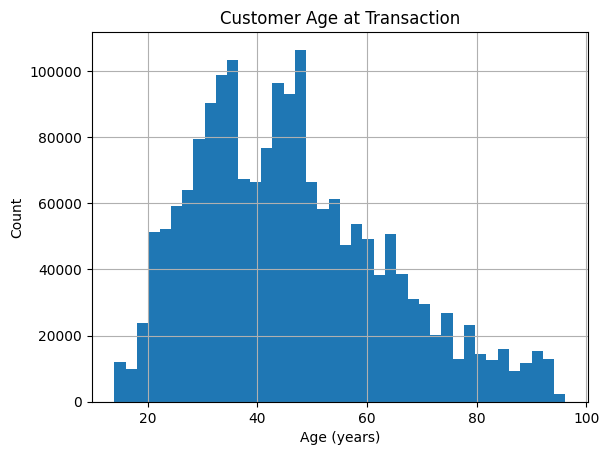

In [23]:

# Calculate customer age at transaction
age = (df['trans_date_trans_time'] - df['dob']).dt.days / 365.25

# Age statistics
print(age.describe())


# Age distribution
age.hist(bins=40)
plt.title('Customer Age at Transaction')
plt.xlabel('Age (years)')
plt.ylabel('Count')
plt.show()


**Note:** The average customer age is 46.26 years, with 50% of transactions involving customers aged approximately 33–57. Ages range from about 14 to 96 years, with no clearly impossible ages observed.